In [2]:
# ============================================================
# 1. Daten, Modelle, Training
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import shapiq
from sklearn.datasets import make_moons
from probly.method import dropout, ensemble
from probly.representer import representer
from probly.quantification import quantify

torch.manual_seed(0)

X, y = make_moons(n_samples=500, noise=0.1, random_state=0)
X_test, _ = make_moons(n_samples=300, noise=0.2, random_state=1)
Xt, yt = torch.from_numpy(X).float(), torch.from_numpy(y).long()
Xt_test = torch.from_numpy(X_test).float()

/Users/tristanfuchs/Test_probly/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


X und Y sind die beides Trainingpunkte mit ihren Labels 

Mit Torch.from_numpy in PyTorch_tenosr umgewandelt 

In [3]:
net = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))
mc  = dropout(net, p=0.2, predictor_type="logit_classifier")
ens = ensemble(net, num_members=5, predictor_type="logit_classifier")

net ist Basisnetz mit 2 -> 64 -> 63 -> 2   

Daraus macht probly dropout (20 %)  und emsamble (5) 

In [4]:
def trainiere(modell, epochen=300):
    opt = torch.optim.Adam(modell.parameters(), lr=0.01)
    modell.train()
    for _ in range(epochen):
        opt.zero_grad()
        nn.CrossEntropyLoss()(modell(Xt), yt).backward()
        opt.step()
    modell.eval()

trainiere(mc)
for m in ens:
    trainiere(m)

Trainieren Standart Schleife

Vorhersage, Fehler messen, Gradient berechen, Gewichte anpassen 

In [5]:
modelle = {"MC-Dropout": representer(mc, num_samples=50), "Ensemble": representer(ens)}

def p_rot_array(rep, punkte):
    return rep.represent(punkte).sample_mean().probabilities.detach().numpy()[:, 1]

Der representer holt viele Vorhersagen pro Punkt: 50 bei MC-Dropout, 5 beim Ensemble. Das Dictionary modelle hält beide zusammen, damit wir später mit einer Schleife über beide laufen können.

Hilfsfunktion p_rot_array

Mittelt die Vorhersagen und gibt P(roter Mond) pro Punkt zurück.

findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


=== PROBLY: Gesamt-Unsicherheit ===
MC-Dropout  Mittel=0.0366  Min=0.0000  Max=0.6924
Ensemble    Mittel=0.0311  Min=0.0000  Max=0.6927

Erste 5 Testpunkte:
Punkt      x1      x2 | MC-Dropout: P(rot)  Unsich. | Ensemble: P(rot)  Unsich.
  0    0.21   -0.02 | 1.000   0.0002 | 1.000   0.0000
  1   -0.83    0.65 | 0.000   0.0000 | 0.000   0.0000
  2    0.24    0.01 | 1.000   0.0002 | 1.000   0.0000
  3    1.04   -0.43 | 0.999   0.0038 | 1.000   0.0004
  4   -0.63    0.42 | 0.000   0.0000 | 0.000   0.0001


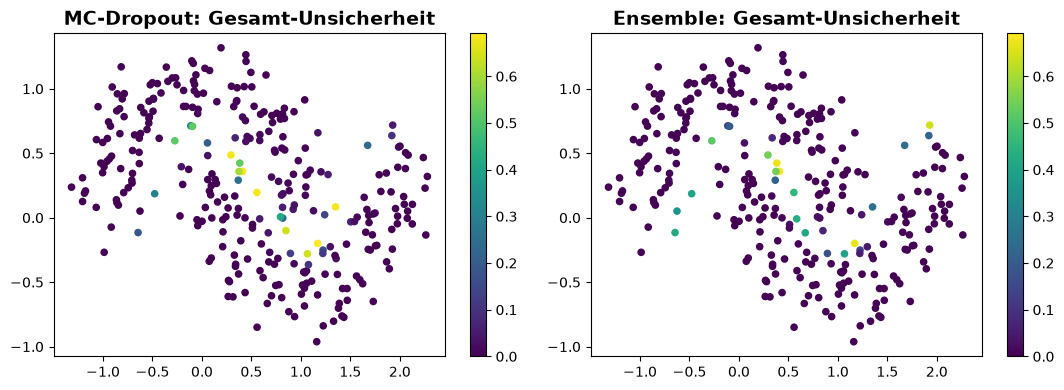

In [6]:
# ============================================================
# 2. Probly: nur die GESAMT-Unsicherheit pro Punkt
# ============================================================
unsicherheit = {name: quantify(rep.represent(Xt_test)).total.detach().numpy()
                for name, rep in modelle.items()}
p_rot = {name: p_rot_array(rep, Xt_test) for name, rep in modelle.items()}

# --- Zahlen ---
print("=== PROBLY: Gesamt-Unsicherheit ===")
for name, u in unsicherheit.items():
    print(f"{name:11s} Mittel={u.mean():.4f}  Min={u.min():.4f}  Max={u.max():.4f}")

print("\nErste 5 Testpunkte:")
print(f"{'Punkt':>3} {'x1':>7} {'x2':>7} | " + " | ".join(f"{n}: P(rot)  Unsich." for n in modelle))
for i in range(5):
    zeile = " | ".join(f"{p_rot[n][i]:.3f}   {unsicherheit[n][i]:.4f}" for n in modelle)
    print(f"{i:>3} {X_test[i,0]:7.2f} {X_test[i,1]:7.2f} | {zeile}")

# --- Grafik ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, u) in zip(axes, unsicherheit.items()):
    sc = ax.scatter(*X_test.T, c=u, cmap="viridis", s=20)
    fig.colorbar(sc, ax=ax); ax.set_title(f"{name}: Gesamt-Unsicherheit")
plt.tight_layout(); plt.show()

Für jedes Modell wird die Unsicherheit der 300 Testpunkte berechnet. Wir nehmen nur .total, also die Gesamt-Unsicherheit ohne Aufteilung in aleatorisch und epistemisch. Dazu speichern wir P(rot) für jeden Punkt.


=== SHAPIQ: Beiträge ===
MC-Dropout  Basiswert=0.510 | Ø|x1|=0.2545  Ø|x2|=0.2278  Ø|x1×x2|=0.2103
Ensemble    Basiswert=0.510 | Ø|x1|=0.2059  Ø|x2|=0.2682  Ø|x1×x2|=0.2078

Erste 5 Testpunkte (shapiq-Beiträge):
Punkt | MC-Dropout:   x1      x2     x1×x2 | Ensemble:   x1      x2     x1×x2
  0 | +0.193  +0.077  +0.220 | +0.215  +0.059  +0.217
  1 | -0.502  -0.307  +0.299 | -0.344  -0.354  +0.189
  2 | +0.178  +0.063  +0.249 | +0.201  +0.049  +0.240
  3 | -0.229  +0.297  +0.422 | -0.214  +0.370  +0.334
  4 | -0.437  -0.137  +0.065 | -0.138  -0.136  -0.236


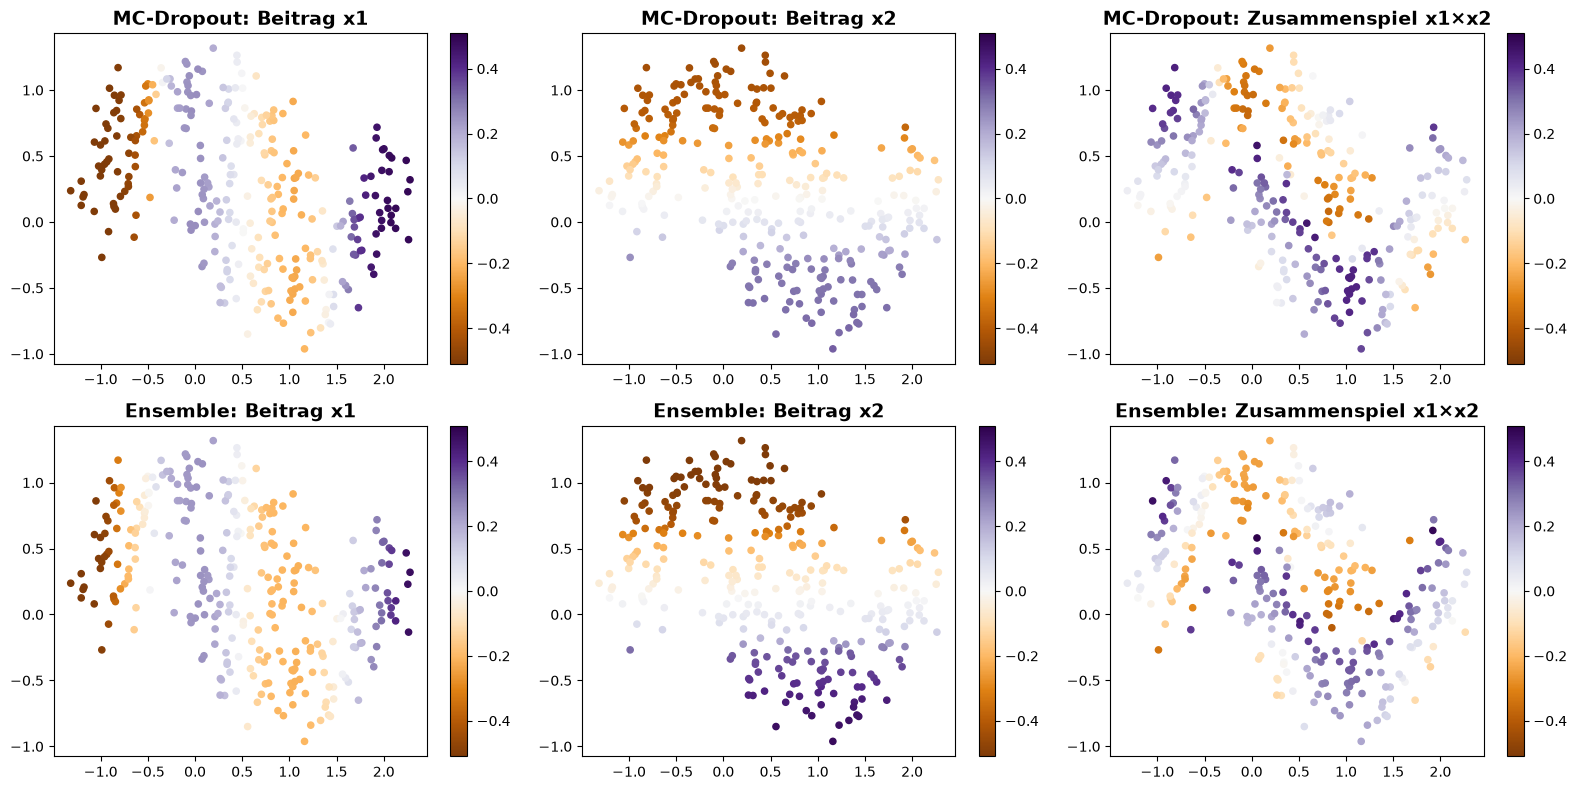

In [7]:
# ============================================================
# 3. shapiq: Beitrag von x1, x2 und x1×x2 pro Punkt
# ============================================================
def p_rot_funktion(rep):
    return lambda pkt: p_rot_array(rep, torch.tensor(pkt, dtype=torch.float32))

hintergrund = X[:100]

shap, basis = {}, {}
for name, rep in modelle.items():
    explainer = shapiq.TabularExplainer(model=p_rot_funktion(rep), data=hintergrund, index="k-SII",
                                        max_order=2, sample_size=None, random_state=0)
    erkl = explainer.explain_X(X_test, budget=4)
    shap[name] = np.array([[e.dict_values.get((0,), 0.0), e.dict_values.get((1,), 0.0),
                            e.dict_values.get((0, 1), 0.0)] for e in erkl])       # x1, x2, x1×x2
    basis[name] = erkl[0].baseline_value

# --- Zahlen ---
print("\n=== SHAPIQ: Beiträge ===")
for name in modelle:
    w = np.abs(shap[name]).mean(0)
    print(f"{name:11s} Basiswert={basis[name]:.3f} | Ø|x1|={w[0]:.4f}  Ø|x2|={w[1]:.4f}  Ø|x1×x2|={w[2]:.4f}")

print("\nErste 5 Testpunkte (shapiq-Beiträge):")
print(f"{'Punkt':>3} | " + " | ".join(f"{n}:   x1      x2     x1×x2" for n in modelle))
for i in range(5):
    zeile = " | ".join(f"{shap[n][i,0]:+.3f}  {shap[n][i,1]:+.3f}  {shap[n][i,2]:+.3f}" for n in modelle)
    print(f"{i:>3} | {zeile}")

# --- Grafik ---
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for r, name in enumerate(modelle):
    for c, titel in enumerate(["Beitrag x1", "Beitrag x2", "Zusammenspiel x1×x2"]):
        g = np.abs(shap[name]).max()
        sc = axes[r, c].scatter(*X_test.T, c=shap[name][:, c], cmap="PuOr", vmin=-g, vmax=g, s=20)
        fig.colorbar(sc, ax=axes[r, c]); axes[r, c].set_title(f"{name}: {titel}")
plt.tight_layout(); plt.show()

shapiq erwartet eine Funktion, die Punkte als NumPy-Array bekommt und eine Zahl zurückgibt. Diese kleine Hülle verpackt unser Modell entsprechend. So erklärt shapiq genau die Modelle, deren Unsicherheit wir eben berechnet haben.

hintergrund: 100 Trainingspunkte, mit denen shapiq „weggelassene“ Merkmale auffüllt
max_order=2: Beiträge für einzelne Merkmale und für das Paar x1×x2
budget=4: Bei 2 Merkmalen gibt es nur 4 Gruppen, shapiq rechnet also alle durch und das Ergebnis ist exakt

Aus jeder Erklärung werden drei Zahlen herausgezogen: Beitrag von x1 ((0,)), von x2 ((1,)) und vom Zusammenspiel ((0, 1)). basis ist der Basiswert, also die durchschnittliche Vorhersage ohne Kenntnis des Punktes.

Zahlen: Mittlerer Betrag der drei Beiträge pro Modell (welches Merkmal ist im Schnitt wichtig?) und die Beiträge der ersten 5 Punkte.

Grafik: Zwei Zeilen (je Modell), drei Spalten (x1, x2, x1×x2). Lila erhöht P(rot), orange senkt es. Die Farbskala ist je Zeile gleich, damit die Spalten vergleichbar sind.

findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.



=== KOMBINATION ===
MC-Dropout  Korrelation (Unsicherheit ↔ Σ|shapiq|) = -0.242
            Ø Σ|shapiq| bei den 25 % sichersten Punkten   = 0.8267
            Ø Σ|shapiq| bei den 25 % unsichersten Punkten = 0.6114
Ensemble    Korrelation (Unsicherheit ↔ Σ|shapiq|) = -0.127
            Ø Σ|shapiq| bei den 25 % sichersten Punkten   = 0.7836
            Ø Σ|shapiq| bei den 25 % unsichersten Punkten = 0.6771


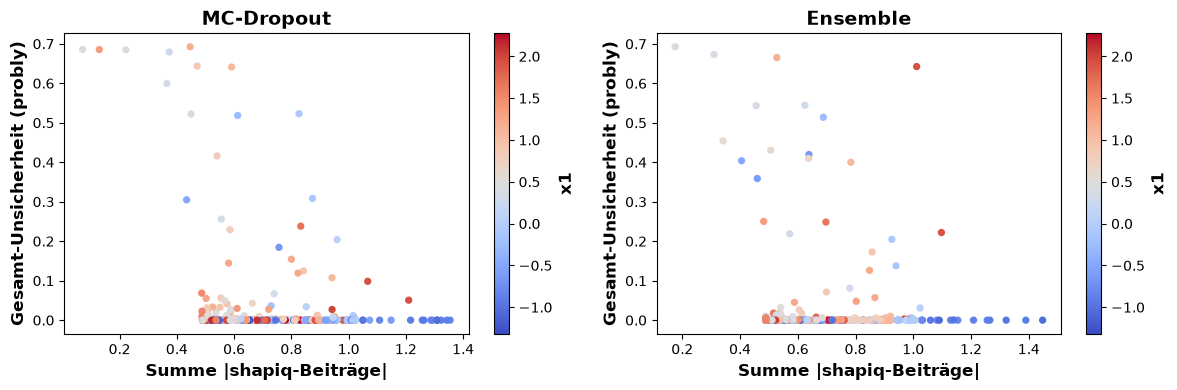

In [8]:
# ============================================================
# 4. Kombination: Unsicherheit und shapiq zusammen
# ============================================================
staerke = {name: np.abs(shap[name]).sum(1) for name in modelle}   # Summe |Beiträge| pro Punkt

# --- Zahlen ---
print("\n=== KOMBINATION ===")
for name in modelle:
    korr = np.corrcoef(staerke[name], unsicherheit[name])[0, 1]
    sicher   = unsicherheit[name] <= np.percentile(unsicherheit[name], 25)
    unsicher = unsicherheit[name] >= np.percentile(unsicherheit[name], 75)
    print(f"{name:11s} Korrelation (Unsicherheit ↔ Σ|shapiq|) = {korr:+.3f}")
    print(f"{'':11s} Ø Σ|shapiq| bei den 25 % sichersten Punkten   = {staerke[name][sicher].mean():.4f}")
    print(f"{'':11s} Ø Σ|shapiq| bei den 25 % unsichersten Punkten = {staerke[name][unsicher].mean():.4f}")

# --- Grafik ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, modelle):
    sc = ax.scatter(staerke[name], unsicherheit[name], c=X_test[:, 0], cmap="coolwarm", s=18)
    ax.set_xlabel("Summe |shapiq-Beiträge|")
    ax.set_ylabel("Gesamt-Unsicherheit (probly)")
    ax.set_title(name)
    fig.colorbar(sc, ax=ax, label="x1")
plt.tight_layout(); plt.show()

Pro Punkt wird die Summe der Beträge der drei shapiq-Beiträge gebildet. Das ist ein einfaches Maß dafür, wie stark die Merkmale bei diesem Punkt insgesamt an der Vorhersage ziehen.

Zahlen:

Die Korrelation zwischen Unsicherheit und dieser Stärke. Nahe +1 heißt: unsichere Punkte haben starke Beiträge. Nahe −1: unsichere Punkte haben schwache Beiträge. Nahe 0: kein klarer Zusammenhang.
Die mittlere Stärke bei den 25 % sichersten gegen die 25 % unsichersten Punkte. Das ist derselbe Zusammenhang noch einmal in Gruppen, leichter zu lesen als die Korrelation.

Grafik: Jeder Punkt hat die Stärke der Beiträge auf der x-Achse und die Unsicherheit auf der y-Achse. Die Farbe zeigt x1. So siehst du in einem Bild, wie das, was probly sagt (wie unsicher), mit dem zusammenhängt, was shapiq sagt (wie stark wirken die Merkmale).


AUSWERTUNG

--- Allgemeine Unsicherheit (Mittel über alle 300 Testpunkte) ---
MC-Dropout  Ø Gesamt-Unsicherheit = 0.0366
Ensemble    Ø Gesamt-Unsicherheit = 0.0311
-> Im Durchschnitt ist MC-Dropout unsicherer.

--- Wichtigkeit laut shapiq (Ø |Beitrag|, Anteil in %) ---
MC-Dropout  x1= 36.8%  x2= 32.9%  x1×x2= 30.4%   (wichtigstes: x1)
Ensemble    x1= 30.2%  x2= 39.3%  x1×x2= 30.5%   (wichtigstes: x2)


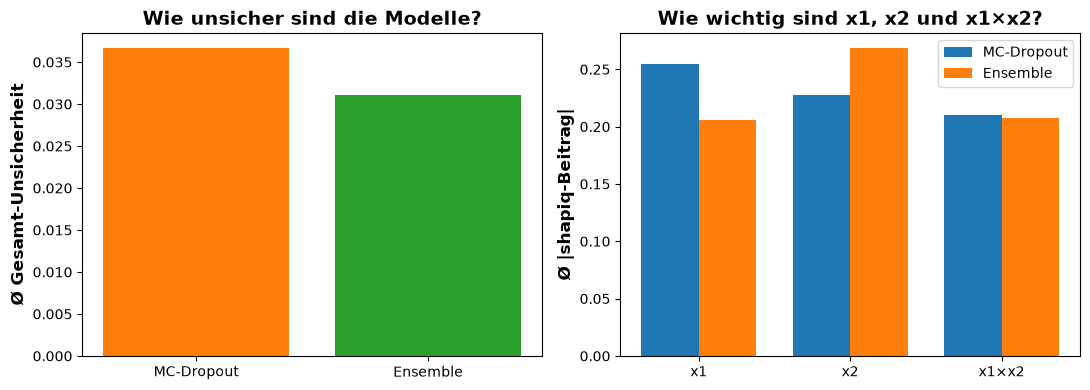

In [9]:
# ============================================================
# 5. Einfache Auswertung
# ============================================================
print("\n" + "=" * 60)
print("AUSWERTUNG")
print("=" * 60)

# --- 5a. Wie unsicher sind die Modelle im Allgemeinen? ---
print("\n--- Allgemeine Unsicherheit (Mittel über alle 300 Testpunkte) ---")
mittel_u = {name: unsicherheit[name].mean() for name in modelle}
for name, wert in mittel_u.items():
    print(f"{name:11s} Ø Gesamt-Unsicherheit = {wert:.4f}")
unsicherer = max(mittel_u, key=mittel_u.get)
print(f"-> Im Durchschnitt ist {unsicherer} unsicherer.")

# --- 5b. Wie wichtig sind x1, x2 und das Zusammenspiel? ---
print("\n--- Wichtigkeit laut shapiq (Ø |Beitrag|, Anteil in %) ---")
namen = ["x1", "x2", "x1×x2"]
wichtigkeit = {}
for name in modelle:
    w = np.abs(shap[name]).mean(0)
    wichtigkeit[name] = w
    anteil = 100 * w / w.sum()
    zeile = "  ".join(f"{n}={a:5.1f}%" for n, a in zip(namen, anteil))
    print(f"{name:11s} {zeile}   (wichtigstes: {namen[int(np.argmax(w))]})")

# --- 5c. Grafik: beides nebeneinander ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(list(mittel_u.keys()), list(mittel_u.values()), color=["tab:orange", "tab:green"])
axes[0].set_ylabel("Ø Gesamt-Unsicherheit")
axes[0].set_title("Wie unsicher sind die Modelle?")

breite, pos = 0.38, np.arange(3)
for i, name in enumerate(modelle):
    axes[1].bar(pos + (i - 0.5) * breite, wichtigkeit[name], breite, label=name)
axes[1].set_xticks(pos, namen)
axes[1].set_ylabel("Ø |shapiq-Beitrag|")
axes[1].set_title("Wie wichtig sind x1, x2 und x1×x2?")
axes[1].legend()

plt.tight_layout(); plt.show()

In [10]:
def unsicherheit_funktion(rep):
    return lambda pkt: quantify(rep.represent(torch.tensor(pkt, dtype=torch.float32))).total.detach().numpy()

explainer_u = shapiq.TabularExplainer(model=unsicherheit_funktion(modelle["Ensemble"]), data=hintergrund,
                                      index="k-SII", max_order=2, sample_size=None, random_state=0)
erkl_u = explainer_u.explain_X(X_test, budget=4)